# Section 1: Setup and the imports
- This is taken from chapter 2.

The possible class labels assigned for every sensor observation are:
1. Sitting on be
2. Sitting on chair
3. Lying on bed
4. Ambulating, where ambulating includes standing, walking around the room.

The placement of the electrode:

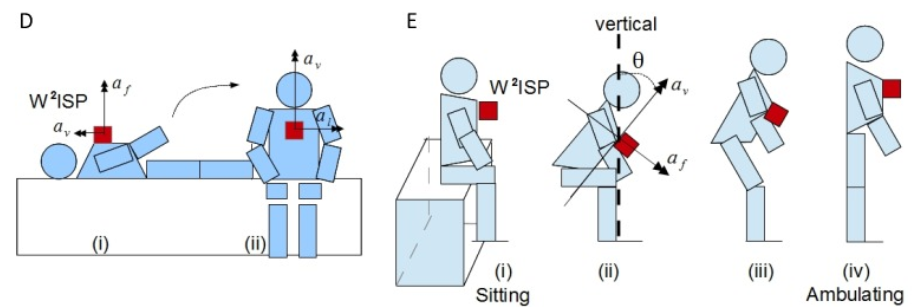

The image is taken from: _https://pmc.ncbi.nlm.nih.gov/articles/PMC4851060/_

In [15]:
# mports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# To make this notebook's output stable across runs :))
np.random.seed(42)

# Scikit-Learn imports
from sklearn.model_selection import train_test_split


In [23]:
# Import the dataset
base_folder = Path(r"C:\Users\nield\Desktop\GitHub\MachineLearningMiniProject\activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor")

# Columns
columns = ["time", "accel_frontal", "accel_vertical", "accel_lateral", "antenna_id", "RSSI", "phase", "frequency", "activity"]

# Open the dataset
dataframes = []

for folder_name in ["S1_Dataset", "S2_Dataset"]:
    for file in (base_folder / folder_name).iterdir():
        if file.is_file():
            try:
                temp_df = pd.read_csv(file, header=None, sep=None, engine="python")

                if temp_df.shape[1] == len(columns):
                    temp_df.columns = columns
                    temp_df["subject_folder"] = folder_name
                    temp_df["source_file"] = file.name
                    dataframes.append(temp_df)
            except Exception:
                pass

df = pd.concat(dataframes, ignore_index=True)

# Prints, can be removed later.
print("The shape of the dataset", df.shape)
df.head() # show the data in a table

The shape of the dataset (75128, 11)


,time,accel_frontal,accel_vertical,accel_lateral,antenna_id,RSSI,phase,frequency,activity,subject_folder,source_file
0,0.00,0.27203,1.00820,-0.082102,1,-63.5,2.4252,924.25,1,S1_Dataset,d1p01M
1,0.50,0.27203,1.00820,-0.082102,1,-63.0,4.7369,921.75,1,S1_Dataset,d1p01M
2,1.50,0.44791,0.91636,-0.013684,1,-63.5,3.0311,923.75,1,S1_Dataset,d1p01M
3,1.75,0.44791,0.91636,-0.013684,1,-63.0,2.0371,921.25,1,S1_Dataset,d1p01M
4,2.50,0.34238,0.96229,-0.059296,1,-63.5,5.8920,920.25,1,S1_Dataset,d1p01M


# EDA - Exploratory Data Analysis
- See the distributions and check for the data quaility before the algotithm.
- This is to see if the dataset is balanced or imbalanced.
- Look below and see that 3

The possible class labels assigned for every sensor observation are:
- Sitting on bed
- Sitting on chair
- Lying on bed
- Ambulating, where ambulating includes standing, walking around the room.

<class 'pandas.DataFrame'>
RangeIndex: 75128 entries, 0 to 75127
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            75128 non-null  float64
 1   accel_frontal   75128 non-null  float64
 2   accel_vertical  75128 non-null  float64
 3   accel_lateral   75128 non-null  float64
 4   antenna_id      75128 non-null  int64  
 5   RSSI            75128 non-null  float64
 6   phase           75128 non-null  float64
 7   frequency       75128 non-null  float64
 8   activity        75128 non-null  int64  
 9   subject_folder  75128 non-null  str    
 10  source_file     75128 non-null  str    
dtypes: float64(7), int64(2), str(2)
memory usage: 6.3 MB


C:\Users\nield\AppData\Local\Temp\ipykernel_18972\2078652701.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='activity', data=df, palette='viridis')


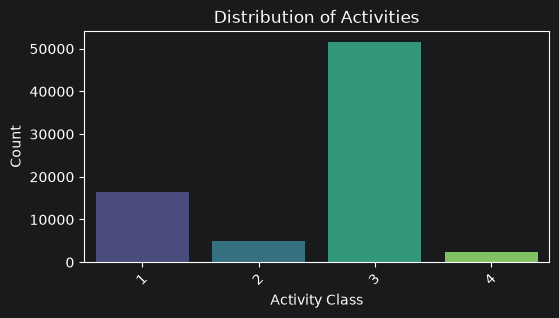

activity
3    0.685763
1    0.218374
2    0.065368
4    0.030495
Name: proportion, dtype: float64


In [25]:
# Inspect the data structure (column data types and missing values (the description says none))
df.info() #

# Checks the summary statistics like mean, min, max.
df.describe()

# Check the class distribution
plt.figure(figsize=(6, 3))
sns.countplot(x='activity', data=df, palette='viridis')
plt.title('Distribution of Activities')
plt.xlabel('Activity Class')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

print(df['activity'].value_counts(normalize=True))

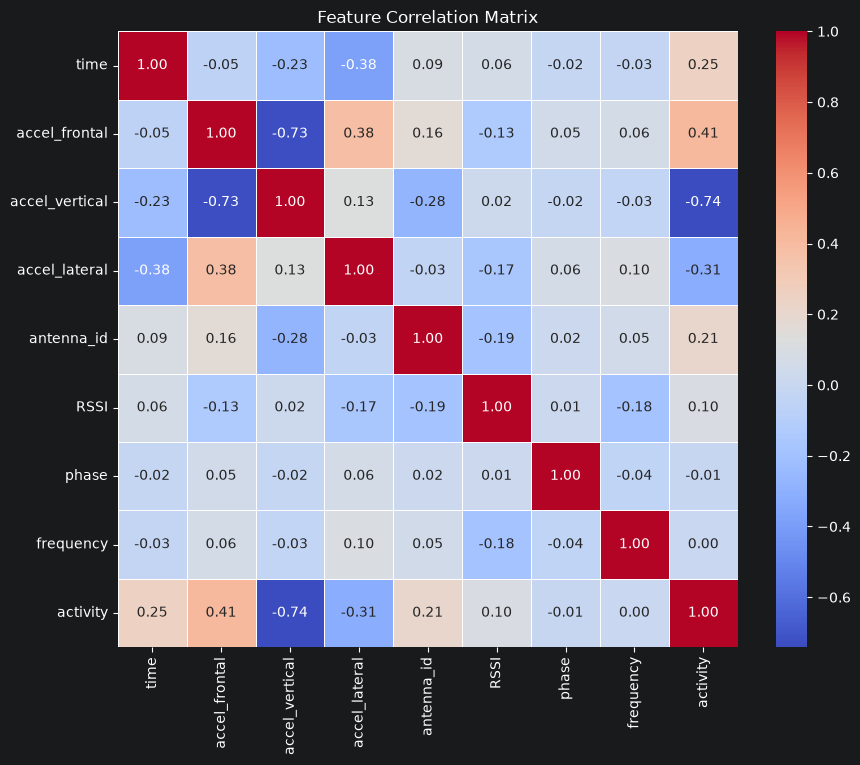

In [32]:
# Compute the correlation matrix
corr_matrix = df.drop(columns=['subject_folder', 'source_file']).corr()

# Plot a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.show()

Here is a visualization of the axies:

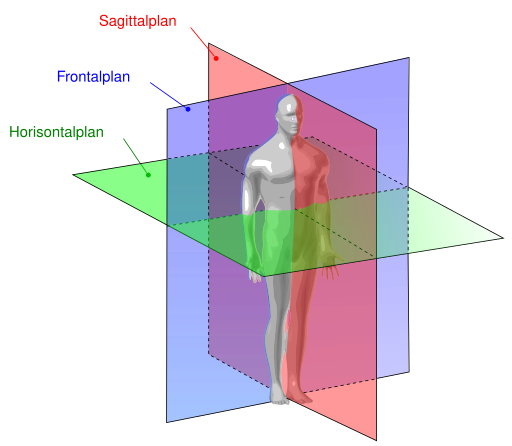

Picture taken from: _https://lex.dk/sagittalplan_

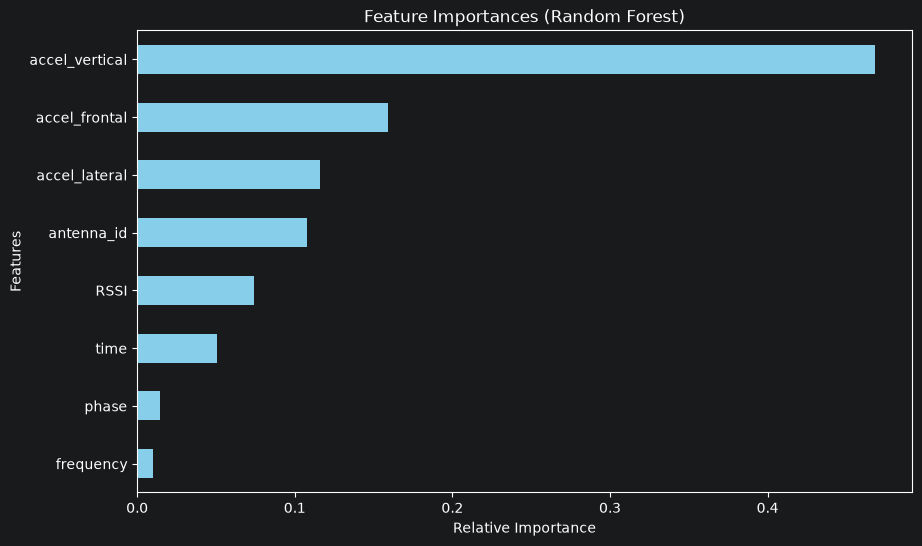

In [33]:
# 'forest_clf' is the trained RandomForestClassifier and X_train are the training features
importances = pd.Series(forest_clf.feature_importances_, index=X_train.columns)

plt.figure(figsize=(10, 6))
importances.sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title("Feature Importances (Random Forest)")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.show()

C:\Users\nield\AppData\Local\Temp\ipykernel_18972\3880038706.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='activity', y='accel_frontal', data=df, palette='Set2')


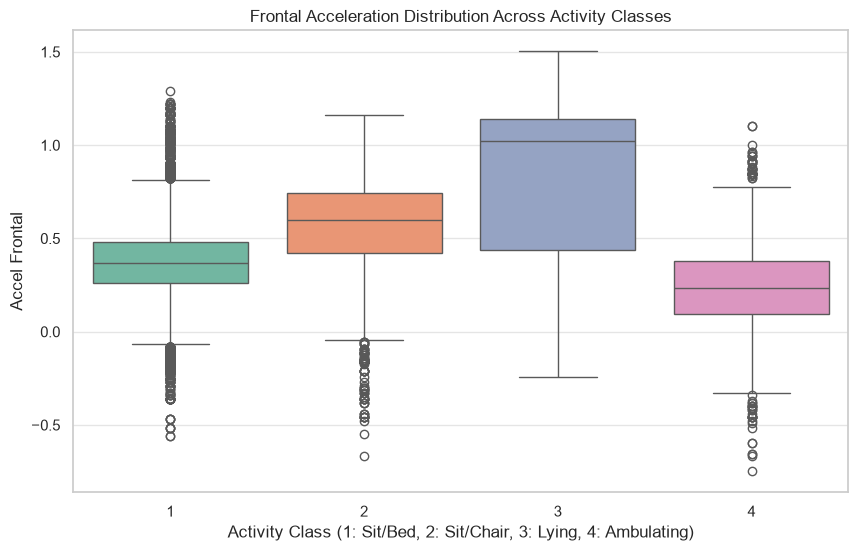

In [34]:
sns.set_theme(style="whitegrid")

# Create boxplots to visualize how frontal acceleration differs by activity
plt.figure(figsize=(10, 6))
sns.boxplot(x='activity', y='accel_frontal', data=df, palette='Set2')
plt.title('Frontal Acceleration Distribution Across Activity Classes')
plt.xlabel('Activity Class (1: Sit/Bed, 2: Sit/Chair, 3: Lying, 4: Ambulating)')
plt.ylabel('Accel Frontal')
plt.show()

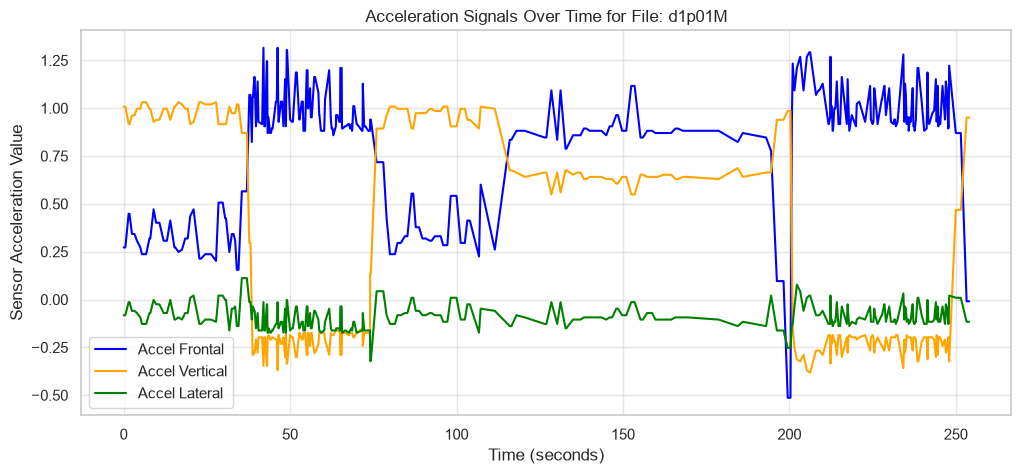

In [44]:
# Filter for a single sample file to inspect continuous sensor readings over time
sample_file_name = df['source_file'].iloc[0]
subset_df = df[df['source_file'] == sample_file_name].head(1000)

plt.figure(figsize=(12, 5))
plt.plot(subset_df['time'], subset_df['accel_frontal'], label='Accel Frontal', color='blue')
plt.plot(subset_df['time'], subset_df['accel_vertical'], label='Accel Vertical', color='orange')
plt.plot(subset_df['time'], subset_df['accel_lateral'], label='Accel Lateral', color='green')
plt.title(f'Acceleration Signals Over Time for File: {sample_file_name}')
plt.xlabel('Time (seconds)')
plt.ylabel('Sensor Acceleration Value')
plt.legend()
plt.show()

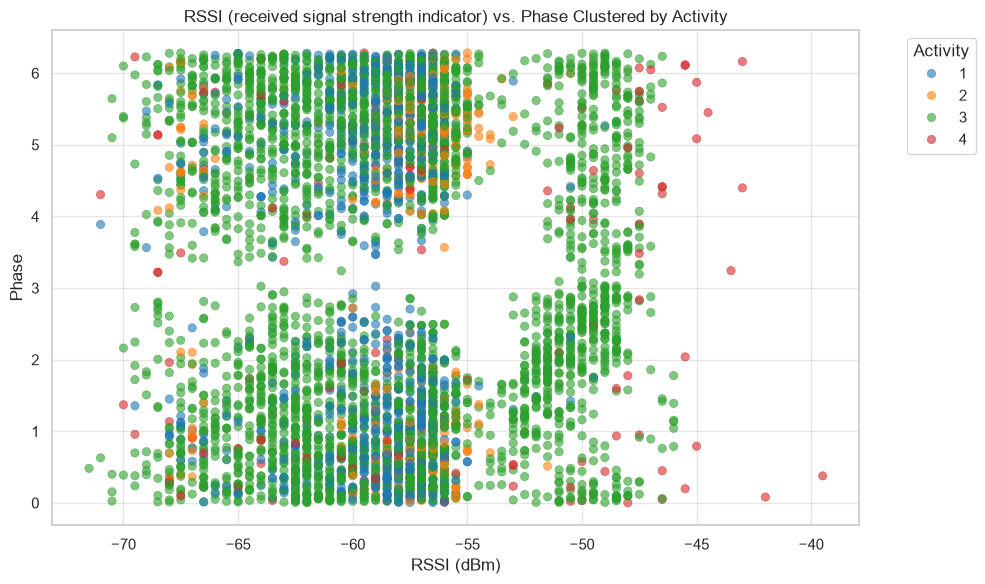

In [37]:
# Scatter plot of RSSI versus Phase, separated by activity
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df.sample(5000, random_state=42),  # Subsample for clear visualization
    x='RSSI',
    y='phase',
    hue='activity',
    palette='tab10',
    alpha=0.6,
    edgecolor=None
)
plt.title('RSSI (received signal strength indicator) vs. Phase Clustered by Activity')
plt.xlabel('RSSI (dBm)')
plt.ylabel('Phase')
plt.legend(title='Activity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Prepare the data
- Random data splitting can introduce a sampling bias, look above.
- Inspiration from Chapter 2, the stratified sampling (stratify=y) using train_test_split(). This makes sure that the train, test and validation have the same porportions of each activity as the complete dataset.

In [30]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['activity', 'subject_folder', 'source_file'])
y = df['activity']

# First split: 70% training, 30% temporary (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# Print dataset shapes
print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")

print(f"\nTraining labels: {y_train.shape}")
print(f"Validation labels: {y_val.shape}")
print(f"Test labels: {y_test.shape}")

Training set shape: (52589, 8)
Validation set shape: (11269, 8)
Test set shape: (11270, 8)

Training labels: (52589,)
Validation labels: (11269,)
Test labels: (11270,)


# Train a model
- Random forest classifier. Random Forests handle non-linear relationships well and requires minimal feature scaling, compared to linear or neural network models.

In [31]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train the Random Forest Classifier
forest_clf = RandomForestClassifier(random_state=42)
forest_clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = forest_clf.predict(X_test)

# Evaluate performance
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.988642413487134

Classification Report:
               precision    recall  f1-score   support

           1       0.97      0.99      0.98      2461
           2       0.98      0.98      0.98       737
           3       1.00      1.00      1.00      7729
           4       0.95      0.78      0.86       343

    accuracy                           0.99     11270
   macro avg       0.97      0.94      0.95     11270
weighted avg       0.99      0.99      0.99     11270



# Fine tuning
- Time for fine tuning the hyperparameters using GridSearchCV or RandomizedSearchCV